# Supervised and unsupervised learning!

## 🗂️ Project structure

1. Following the task description, you'll find a set of formal requirements that your solution must meet.
2. The primary measure of your success is the **test** performance of your model, as specified in each problem.
3. After completing each task, you must answer a series of questions, marked with ❓, to demonstrate your understanding of the techniques used.
4. You may create as many cells as needed, but the final results should be kept in a short and simple cell.

## 📝 Submission guidelines

- For each problem, provide your code solution and model results inside this notebook.
- Answer the follow-up questions in markdown format within this notebook. A few sentences is enough, no requirements for length of answers.
- Ensure your explanations are clear, concise, and demonstrate a deep understanding of the techniques employed.
- Submit this notebook (**problem.ipynb**) to Canvas. Deliver the notebook such that outputs are saved, ideally *restart* the kernel followed by *run all*.
- Use Kaggle to check your cluster assignments while you work. More details are in the problem description.
- Include your final **submission.csv** in the Canvas delivery, together with this notebook.

Good luck!

---


# 🎯 Problem 1: Training Neural Networks

### ❗️ The problem

Train neural networks for:
- A binary classification problem
- A non-linear regression problem

To reach the target performance, you may want to experiment with optimization techniques such as:
- Full-batch vs. mini-batch training
- Learning-rate scheduling (e.g., cosine annealing)
- Hyperparameter tuning (learning rate, batch size, depth, width)
- Optimizers (e.g., Adam, RMSprop, SGD)
- Activation functions (e.g., sigmoid, tanh, ReLU, GELU)
- Early stopping
- And more!

### 📋 Formal requirements

1. **Implementation**
   - Use Tensorflow/Keras or PyTorch for each problem (for Keras, you may find these guides useful: [Sequential model](https://keras.io/guides/sequential_model/) and [Training with built-in methods](https://keras.io/guides/training_with_built_in_methods/))
   - Try **at least three** of the techniques listed above.
   - Results must be **reproducible**: rerunning the notebook should yield the same metrics (fix random seeds).

2. **Performance**
   - **Classification**: at least **90% accuracy on the test set**.
   - **Regression**: at most **0.25 RMSE** on the test inputs, scored by `plot_complex_fit`.

3. **Discussion**
   - How did you ensure reproducibility?
   - Visualize/explain the network architecture for both classification and regression (e.g., block diagram, parameter counts, activation functions, etc.).
   - Plot the classification **decision boundary** with `plot_decision_boundary` from `utils`. Would the model generalize to larger feature values?
   - Plot train and held-out loss vs. epoch for classification and for regression. What do these curves tell you? Are the final values a good way to judge the model performance?
   - Which optimization techniques did you try? What worked and what did not?


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN, KMeans
from utils import plot_complex_fit, plot_decision_boundary
# Any other imports you need
import random

import torch
import torch.nn as nn
from scipy.ndimage import map_coordinates
from sklearn.cluster import SpectralClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

SEED = 0


def set_seed(seed=SEED):
    """Fix every source of randomness used in this notebook."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


torch.use_deterministic_algorithms(True)
torch.set_num_threads(1)  # single thread: identical floating point results on every run
set_seed()

import warnings
warnings.filterwarnings("ignore", message="Graph is not fully connected")
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)

## Binary classification


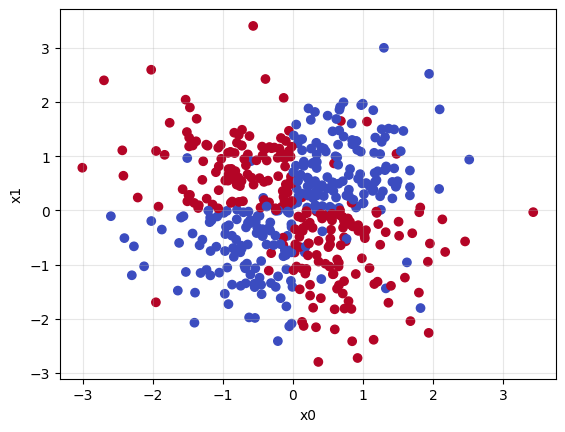

In [2]:
# This is our problem... It's basically XOR, but with continuous values (and a lot of noise!)
data = pd.read_csv("classification_data.csv")
train = data[data["split"] == "train"]
test = data[data["split"] == "test"]

plt.scatter(test["x0"], test["x1"], c=test["y"], cmap="coolwarm")
plt.xlabel("x0")
plt.ylabel("x1")
plt.grid(True, alpha=0.3)
plt.show()

In [3]:
# ====================================
# YOUR CODE GOES HERE
# ====================================

In [4]:
def make_mlp(n_in, width, depth, act):
    layers, d = [], n_in
    for _ in range(depth):
        layers += [nn.Linear(d, width), act()]
        d = width
    return nn.Sequential(*layers, nn.Linear(d, 1))


def train_net(X, y, train_idx, val_idx, *, act, width, depth, opt="adam", lr=3e-3, batch_size=32,
              epochs=300, cosine=True, patience=None, weight_decay=0.0, loss_fn=None, seed=SEED):
    """Train an MLP. Returns the model restored to the epoch with the lowest held-out loss, and the loss history."""
    set_seed(seed)
    g = torch.Generator().manual_seed(seed)
    net = make_mlp(X.shape[1], width, depth, act)
    optimizers = {
        "adam": lambda p: torch.optim.AdamW(p, lr=lr, weight_decay=weight_decay),
        "sgd": lambda p: torch.optim.SGD(p, lr=lr, momentum=0.9),
        "rmsprop": lambda p: torch.optim.RMSprop(p, lr=lr),
    }
    optimizer = optimizers[opt](net.parameters())
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, epochs) if cosine else None
    history = {"train": [], "val": []}
    best = (np.inf, None, 0)
    for epoch in range(epochs):
        net.train()
        perm = train_idx[torch.randperm(len(train_idx), generator=g)]
        for b in range(0, len(perm), batch_size):
            j = perm[b:b + batch_size]
            loss = loss_fn(net(X[j]).squeeze(1), y[j])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        if scheduler:
            scheduler.step()
        net.eval()
        with torch.no_grad():
            history["train"].append(loss_fn(net(X[train_idx]).squeeze(1), y[train_idx]).item())
            history["val"].append(loss_fn(net(X[val_idx]).squeeze(1), y[val_idx]).item())
        if history["val"][-1] < best[0]:
            best = (history["val"][-1], {k: v.clone() for k, v in net.state_dict().items()}, epoch)
        elif patience is not None and epoch - best[2] > patience:
            break
    net.load_state_dict(best[1])
    net.eval()
    history["best_epoch"] = best[2]
    return net, history


def count_params(net):
    return sum(p.numel() for p in net.parameters())


# Data: hold out 100 of the 500 training rows for early stopping and model selection.
Xc_train = torch.tensor(train[["x0", "x1"]].values, dtype=torch.float32)
yc_train = torch.tensor(train["y"].values, dtype=torch.float32)
Xc_test = torch.tensor(test[["x0", "x1"]].values, dtype=torch.float32)
yc_test = test["y"].values
perm = torch.randperm(len(Xc_train), generator=torch.Generator().manual_seed(SEED))
c_val_idx, c_train_idx = perm[:100], perm[100:]
bce = nn.BCEWithLogitsLoss()


def cls_run(**kw):
    net, hist = train_net(Xc_train, yc_train, c_train_idx, c_val_idx, loss_fn=bce, **kw)
    with torch.no_grad():
        val_acc = ((net(Xc_train[c_val_idx]).squeeze(1) > 0).numpy() == yc_train[c_val_idx].numpy()).mean()
        test_acc = ((net(Xc_test).squeeze(1) > 0).numpy() == yc_test).mean()
    return net, hist, val_acc, test_acc

In [5]:
# Experiments: activation, optimizer, full batch vs mini batch, cosine schedule vs constant LR, depth/width.
# All runs use early stopping on the held-out split (patience 40 epochs).
configs = [
    dict(act=nn.Tanh, width=16, depth=2, opt="adam", lr=3e-3, batch_size=32, cosine=True),
    dict(act=nn.Tanh, width=16, depth=2, opt="adam", lr=3e-3, batch_size=32, cosine=False),
    dict(act=nn.Tanh, width=16, depth=2, opt="adam", lr=1e-2, batch_size=400, cosine=True),
    dict(act=nn.Tanh, width=16, depth=2, opt="sgd", lr=3e-2, batch_size=32, cosine=True),
    dict(act=nn.Tanh, width=16, depth=2, opt="rmsprop", lr=3e-3, batch_size=32, cosine=True),
    dict(act=nn.ReLU, width=16, depth=2, opt="adam", lr=3e-3, batch_size=32, cosine=True),
    dict(act=nn.GELU, width=16, depth=2, opt="adam", lr=3e-3, batch_size=32, cosine=True),
    dict(act=nn.Sigmoid, width=16, depth=2, opt="adam", lr=3e-3, batch_size=32, cosine=True),
    dict(act=nn.Tanh, width=64, depth=3, opt="adam", lr=3e-3, batch_size=32, cosine=True),
]
rows = []
for cfg in configs:
    _, hist, val_acc, test_acc = cls_run(**cfg, patience=40)
    rows.append({"activation": cfg["act"].__name__, "width x depth": f'{cfg["width"]}x{cfg["depth"]}', "optimizer": cfg["opt"],
                 "lr": cfg["lr"], "batch": cfg["batch_size"], "cosine": cfg["cosine"],
                 "best epoch": hist["best_epoch"], "val acc": val_acc, "test acc": test_acc})
pd.DataFrame(rows)

,activation,width x depth,optimizer,lr,batch,cosine,best epoch,val acc,test acc
0,Tanh,16x2,adam,0.003,32,True,26,0.91,0.916
1,Tanh,16x2,adam,0.003,32,False,26,0.91,0.914
2,Tanh,16x2,adam,0.010,400,True,54,0.91,0.904
3,Tanh,16x2,sgd,0.030,32,True,43,0.89,0.908
4,Tanh,16x2,rmsprop,0.003,32,True,26,0.89,0.896
5,ReLU,16x2,adam,0.003,32,True,17,0.90,0.910
6,GELU,16x2,adam,0.003,32,True,10,0.91,0.878
7,Sigmoid,16x2,adam,0.003,32,True,178,0.90,0.892
8,Tanh,64x3,adam,0.003,32,True,64,0.91,0.900


In [6]:
# Final classifier: 2 -> 16 -> 16 -> 1, tanh, Adam (lr 3e-3), mini batches of 32, cosine annealing, early stopping.
CLS_CONFIG = dict(act=nn.Tanh, width=16, depth=2, opt="adam", lr=3e-3, batch_size=32, cosine=True, patience=40)
cls_net, cls_hist, cls_val_acc, cls_test_acc = cls_run(**CLS_CONFIG)
print(f"Classification test accuracy: {cls_test_acc:.3f}  (requirement >= 0.90)")

Classification test accuracy: 0.916  (requirement >= 0.90)


### ❓ Plot the classification decision boundary. Would the model generalize to larger feature values?

Inside the data range (|x| < 3) the boundary follows the two axes almost exactly, which is the XOR rule (y = 1 when x0·x1 < 0). Test accuracy is 91.6%; the ideal rule sign(x0·x1) gets 95%, so the remaining errors are mostly label noise.

The model would **not** generalize reliably to larger feature values. In the second plot (range ±12) the boundary drifts away from the axes, the tanh units saturate and the network extrapolates along diagonal rays, and a spurious region appears in the upper right corner (around x0 ≈ 5, x1 ≈ 10) where the prediction is wrong. There is no training data there, so nothing forces the network to keep the axis aligned XOR structure. The model only knows the pattern where it has seen data.


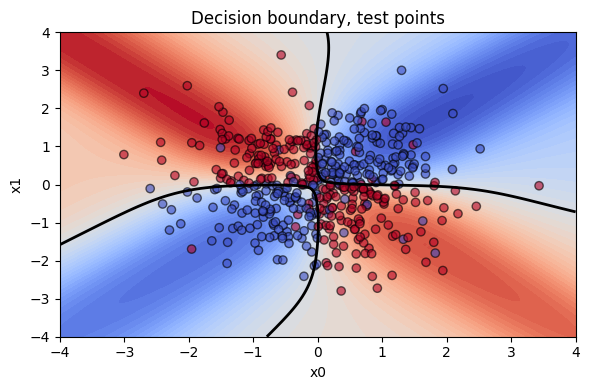

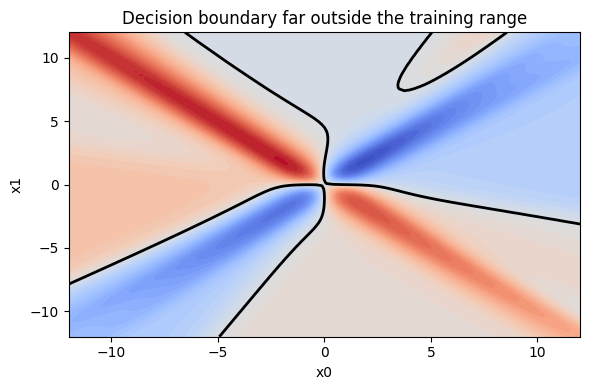

In [7]:
cls_score = lambda pts: cls_net(torch.tensor(pts, dtype=torch.float32)).detach().numpy()
plot_decision_boundary(cls_score, threshold=0.0, points=test[["x0", "x1"]].values, labels=test["y"].values)
plt.title("Decision boundary, test points")
plt.show()
plot_decision_boundary(cls_score, xlim=(-12, 12), ylim=(-12, 12), threshold=0.0)
plt.title("Decision boundary far outside the training range")
plt.show()

## Regression


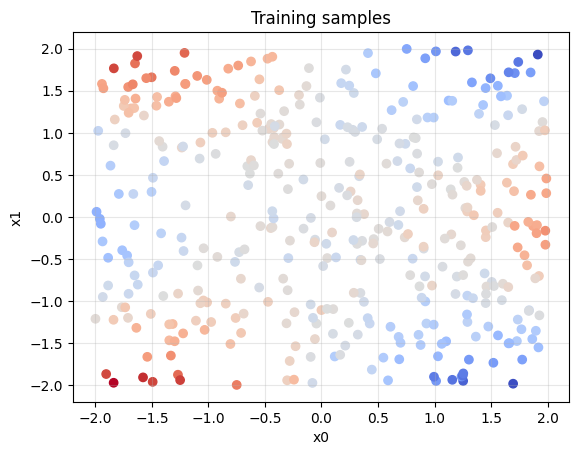

In [8]:
# We have a new dataset now. This time, the target is continuous.
# Test rows have no y. For a validation split, hold out part of train.
data = pd.read_csv("regression_data.csv")
train = data[data["split"] == "train"]
test = data[data["split"] == "test"]

plt.scatter(train["x0"], train["x1"], c=train["y"], cmap="coolwarm")
plt.xlabel("x0")
plt.ylabel("x1")
plt.title("Training samples")
plt.grid(True, alpha=0.3)
plt.show()

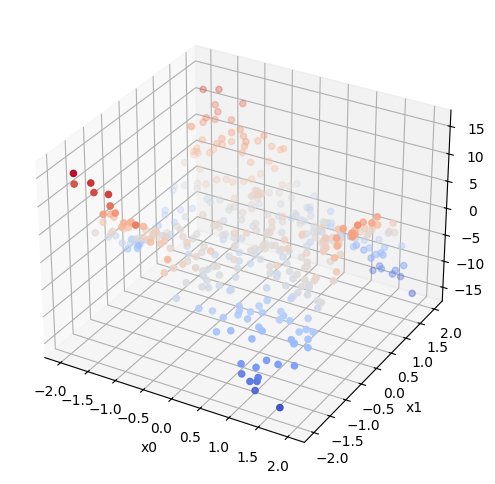

In [9]:
# Hmmm, maybe 3d is better
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(train["x0"], train["x1"], train["y"], c=train["y"], cmap="coolwarm")
ax.set_xlabel("x0")
ax.set_ylabel("x1")
ax.set_zlabel("y")
plt.show()

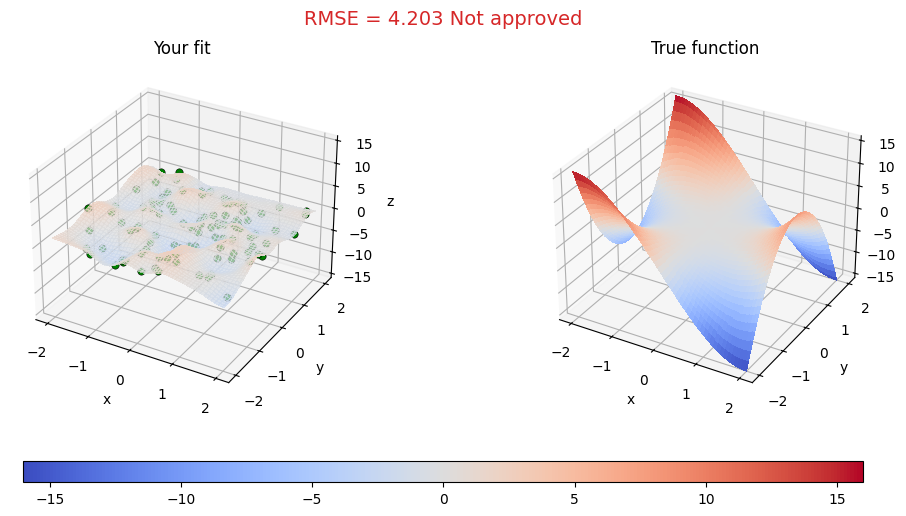

In [10]:
# plot_complex_fit compares your predictions to the true surface and prints RMSE
# plot_complex_fit has no noise, so expect a lower RMSE here
# The test rows have no y, so this is how you score them.
test_xy = test[["x0", "x1"]].values
y_pred_demo = np.random.randn(len(test))
plot_complex_fit(test_xy, y_pred_demo)
plt.show()

# Random predictions fail the 0.25 RMSE threshold.

In [11]:
# ====================================
# YOUR CODE GOES HERE
# ====================================

In [12]:
Xr_train = torch.tensor(train[["x0", "x1"]].values, dtype=torch.float32)
yr_train = torch.tensor(train["y"].values, dtype=torch.float32)
Xr_test = torch.tensor(test_xy, dtype=torch.float32)
mse = nn.MSELoss()
noise_var = np.var(train["y"].values - (train["x0"] ** 3 - 3 * train["x0"] * train["x1"] ** 2))
folds = np.random.default_rng(SEED).permutation(np.arange(len(Xr_train)) % 5)


def true_rmse(pred):
    """RMSE against the noise free surface, the same number plot_complex_fit reports."""
    f = test_xy[:, 0] ** 3 - 3 * test_xy[:, 0] * test_xy[:, 1] ** 2
    return float(np.sqrt(np.mean((np.ravel(pred) - f) ** 2)))


def reg_ensemble(n_models=5, **cfg):
    """K-fold ensemble: model k trains on 4/5 of the data and early-stops on the remaining fold."""
    models, hists = [], []
    for k in range(n_models):
        tr_idx = torch.tensor(np.where(folds != k)[0])
        va_idx = torch.tensor(np.where(folds == k)[0])
        net, hist = train_net(Xr_train, yr_train, tr_idx, va_idx, loss_fn=mse, seed=k, **cfg)
        models.append(net)
        hists.append(hist)
    return models, hists


def predict(models, X):
    with torch.no_grad():
        return np.mean([m(X).squeeze(1).numpy() for m in models], axis=0)

In [13]:
# Experiments (each row is a 5-fold ensemble, plus the mean RMSE of its single members).
configs = [
    dict(act=nn.ReLU, width=64, depth=3, lr=3e-3, batch_size=320),
    dict(act=nn.Tanh, width=64, depth=3, lr=3e-3, batch_size=320),
    dict(act=nn.GELU, width=64, depth=3, lr=3e-3, batch_size=320),
    dict(act=nn.SiLU, width=64, depth=3, lr=3e-3, batch_size=320),
    dict(act=nn.SiLU, width=64, depth=3, lr=3e-3, batch_size=32),
    dict(act=nn.SiLU, width=64, depth=3, lr=1e-2, batch_size=320),
    dict(act=nn.SiLU, width=128, depth=3, lr=3e-3, batch_size=320),
]
rows = []
for cfg in configs:
    models, _ = reg_ensemble(**cfg, epochs=800)
    singles = [true_rmse(predict([m], Xr_test)) for m in models]
    rows.append({"activation": cfg["act"].__name__, "width x depth": f'{cfg["width"]}x{cfg["depth"]}', "lr": cfg["lr"],
                 "batch": "full" if cfg["batch_size"] >= 320 else cfg["batch_size"],
                 "single model RMSE (mean)": np.mean(singles), "ensemble RMSE": true_rmse(predict(models, Xr_test))})
pd.DataFrame(rows)

,activation,width x depth,lr,batch,single model RMSE (mean),ensemble RMSE
0,ReLU,64x3,0.003,full,0.418465,0.340330
1,Tanh,64x3,0.003,full,0.299648,0.252635
2,GELU,64x3,0.003,full,0.317677,0.254627
3,SiLU,64x3,0.003,full,0.289626,0.233379
4,SiLU,64x3,0.003,32,0.371342,0.236123
5,SiLU,64x3,0.010,full,0.338373,0.268338
6,SiLU,128x3,0.003,full,0.283266,0.214782


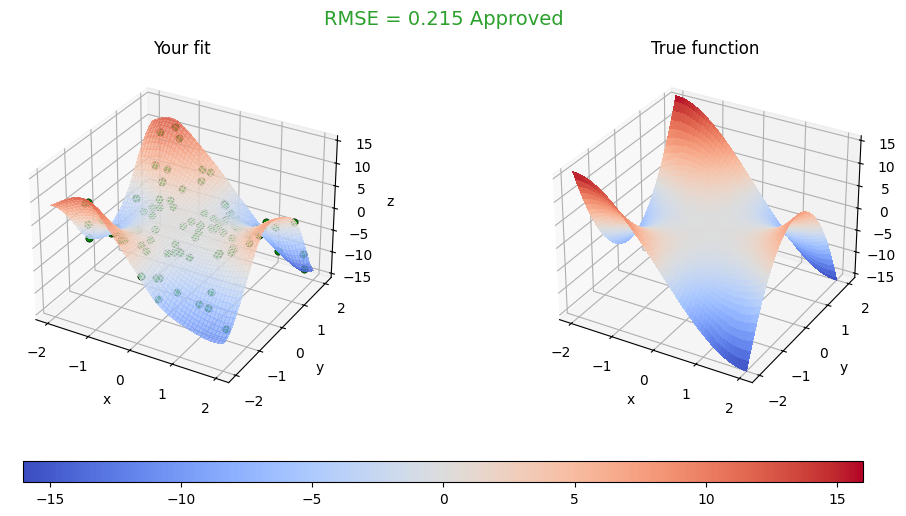

Regression test RMSE: 0.215  (requirement <= 0.25)


In [14]:
# Final regressor: 5-fold ensemble of 2 -> 128 -> 128 -> 128 -> 1 SiLU networks,
# full batch AdamW (lr 3e-3), cosine annealing over 800 epochs, early stopping checkpoint per fold.
REG_CONFIG = dict(act=nn.SiLU, width=128, depth=3, lr=3e-3, batch_size=320, epochs=800)
reg_models, reg_hists = reg_ensemble(**REG_CONFIG)
y_pred = predict(reg_models, Xr_test)
_, _, reg_rmse = plot_complex_fit(test_xy, y_pred)
plt.show()
print(f"Regression test RMSE: {reg_rmse:.3f}  (requirement <= 0.25)")

### ❓ Visualize the network architecture for both classification and regression.

**Classifier:** fully connected network 2 → 16 → 16 → 1 with tanh in both hidden layers, 337 parameters (48 + 272 + 17). The output is a logit; the sigmoid is applied inside `BCEWithLogitsLoss`, and the decision rule is logit > 0. A small network is enough because the true boundary (the two axes) is simple, and fewer parameters overfit the noise less.

**Regressor:** ensemble of 5 networks, each 2 → 128 → 128 → 128 → 1 with SiLU activations and a linear output, 33 537 parameters per network. The prediction is the mean of the 5 networks. Each member is trained on 4/5 of the training rows and early stopped on the remaining fold (5 fold cross validation ensemble). SiLU is smooth, which suits the smooth cubic target x³ − 3xy².


Classifier: 337 trainable parameters
  [0] Linear(in_features=2, out_features=16, bias=True)   params=48
  [1] Tanh()
  [2] Linear(in_features=16, out_features=16, bias=True)   params=272
  [3] Tanh()
  [4] Linear(in_features=16, out_features=1, bias=True)   params=17
Regressor (one of 5 ensemble members): 33537 trainable parameters
  [0] Linear(in_features=2, out_features=128, bias=True)   params=384
  [1] SiLU()
  [2] Linear(in_features=128, out_features=128, bias=True)   params=16512
  [3] SiLU()
  [4] Linear(in_features=128, out_features=128, bias=True)   params=16512
  [5] SiLU()
  [6] Linear(in_features=128, out_features=1, bias=True)   params=129


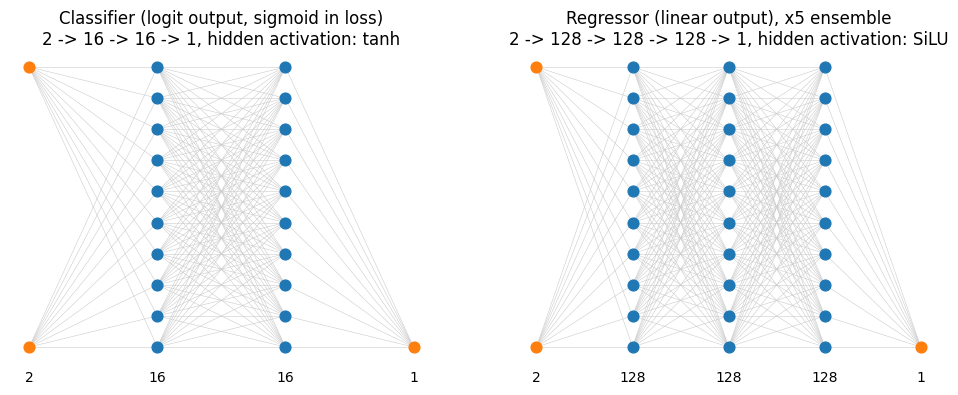

In [15]:
def describe(net, name):
    print(f"{name}: {count_params(net)} trainable parameters")
    for i, layer in enumerate(net):
        n = sum(p.numel() for p in layer.parameters())
        print(f"  [{i}] {layer}" + (f"   params={n}" if n else ""))


def draw_architecture(ax, sizes, act, title):
    ax.axis("off")
    xs = np.linspace(0, 1, len(sizes))
    for k, (x, n) in enumerate(zip(xs, sizes)):
        shown = min(n, 10)
        ys = np.linspace(0.1, 0.9, shown)
        ax.scatter([x] * shown, ys, s=60, zorder=3, color="tab:blue" if 0 < k < len(sizes) - 1 else "tab:orange")
        ax.text(x, 0.0, f"{n}", ha="center")
        if k:
            for y0 in np.linspace(0.1, 0.9, min(sizes[k - 1], 10)):
                for y1 in ys:
                    ax.plot([xs[k - 1], x], [y0, y1], color="0.8", lw=0.4)
    ax.set_title(f"{title}\n{' -> '.join(map(str, sizes))}, hidden activation: {act}")


describe(cls_net, "Classifier")
describe(reg_models[0], "Regressor (one of 5 ensemble members)")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
draw_architecture(axes[0], [2, 16, 16, 1], "tanh", "Classifier (logit output, sigmoid in loss)")
draw_architecture(axes[1], [2, 128, 128, 128, 1], "SiLU", "Regressor (linear output), x5 ensemble")
plt.show()

### ❓ Plot train and held-out loss vs. epoch. What do these curves tell you? Are the final values a good way to judge the model?

**Classification:** train loss keeps decreasing, while held-out loss stops improving after about 20 epochs and then slowly rises. From that point the network starts fitting noise (overfitting). Early stopping keeps the checkpoint from epoch 26 with the lowest held-out loss.

**Regression:** train MSE drops to about 0.9, which is *below* the noise variance (≈ 1.06), so the networks are partly fitting noise. Held-out MSE flattens at 1.3 to 1.6 depending on the fold. The best checkpoints come early and later epochs give no improvement.

**Are the final values a good way to judge the model?** No.
- The final epoch is not the model we use; we keep the early stopping checkpoint.
- The final train loss is optimistic, because the model has seen these points.
- The held-out sets are small (100 and 80 rows), so the curves are noisy and the value depends on which rows ended up in the split (the regression folds differ by 0.3 MSE).
- In regression the held-out MSE is dominated by irreducible noise (≈ 1.06). A held-out MSE of 1.3 says little about how close we are to the true surface. The correct measure is RMSE against the noise free function (0.215).
- In classification the BCE loss also penalizes confidence, while the actual metric is accuracy.

The curves are best used to choose when to stop and to detect overfitting, and the model is judged on the test metric.


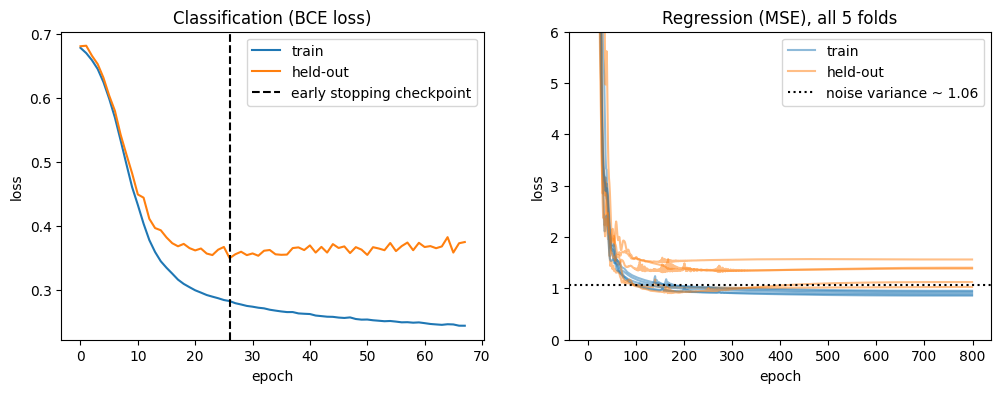

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(cls_hist["train"], label="train")
ax[0].plot(cls_hist["val"], label="held-out")
ax[0].axvline(cls_hist["best_epoch"], color="k", ls="--", label="early stopping checkpoint")
ax[0].set(title="Classification (BCE loss)", xlabel="epoch", ylabel="loss")
ax[0].legend()
for k, h in enumerate(reg_hists):
    ax[1].plot(h["train"], color="tab:blue", alpha=0.5, label="train" if k == 0 else None)
    ax[1].plot(h["val"], color="tab:orange", alpha=0.5, label="held-out" if k == 0 else None)
ax[1].axhline(noise_var, color="k", ls=":", label=f"noise variance ~ {noise_var:.2f}")
ax[1].set(title="Regression (MSE), all 5 folds", xlabel="epoch", ylabel="loss", ylim=(0, 6))
ax[1].legend()
plt.show()

### ❓ Which optimization techniques did you try? What worked and what did not?

Tried: **mini batch vs full batch**, **cosine annealing vs constant learning rate**, **optimizers** (Adam/AdamW, SGD with momentum, RMSprop), **activations** (tanh, ReLU, GELU, sigmoid, SiLU), **width/depth**, **learning rate**, **early stopping**, and for regression a **5 fold ensemble**. See the two tables above.

**Classification**
- Worked: tanh + Adam + mini batches of 32 + cosine annealing + early stopping (91.6%).
- Small effect: constant LR (91.4%), SGD with momentum (90.8%), ReLU (91.0%).
- Worse: full batch (90.4%, converges to a smoother but slightly worse solution), RMSprop (89.6%), sigmoid (89.2%, slow training because of vanishing gradients), GELU (87.8%), a larger 64×3 network (90.0%, overfits more).
- Early stopping mattered most: without it held-out loss increases and accuracy drops.

**Regression**
- Ensembling made the biggest difference: single networks reach about 0.28 to 0.42 RMSE, averaging 5 fold models gives 0.215. Averaging reduces variance, which is the main source of error with 400 noisy points.
- Smooth activations beat ReLU (ReLU ensemble 0.34, tanh 0.25, GELU 0.25, SiLU 0.23), since a piecewise linear fit approximates a smooth cubic poorly with little data.
- Full batch training was better than mini batches for single models (0.29 vs 0.37 mean RMSE). Less gradient noise gives a smoother fit.
- Learning rate 1e-2 was worse than 3e-3. A wider network (128) was slightly better than 64.


### ❓ How did you ensure reproducibility?

- `set_seed()` fixes the seeds for `random`, `numpy` and `torch` before every training run, and each run gets an explicit seed.
- Data shuffling and the train/held-out split use their own seeded `torch.Generator`, and the regression folds use `np.random.default_rng(SEED)`.
- `torch.use_deterministic_algorithms(True)` and `torch.set_num_threads(1)` make the floating point operations run in the same order every time (multithreaded CPU reductions can otherwise change the last digits).
- All scikit-learn methods (PCA, t-SNE, KMeans, spectral clustering) get `random_state=SEED`.

The notebook was restarted and run from scratch several times, and it gave identical results each time (91.6% and RMSE 0.215).


## ✅ Problem 1 results
Classification test accuracy 0.916 (≥ 0.90), regression test RMSE 0.215 (≤ 0.25).

In [17]:
print(f"Classification test accuracy: {cls_test_acc:.3f}  (>= 0.90)")
print(f"Regression test RMSE:         {reg_rmse:.3f}  (<= 0.25)")

Classification test accuracy: 0.916  (>= 0.90)
Regression test RMSE:         0.215  (<= 0.25)


# 🤖 Problem 2: Unsupervised Learning

### ❗️ The problem

1. Identify the number of clusters in the dataset.
2. Assign a cluster label to every row and validate on [Kaggle](https://www.kaggle.com/t/bce19782f3e4447e9bc9de37f36cee86) until you reach at least **99%** clustering accuracy.
3. Visualize the clusters in 2D, and identify what each cluster is.
4. Some rows do not belong with the others. Find those rows and show what they are.

### 💡 Hints

1. **Large Dataset**: The data set **unsupervised_data.csv** is huge! There are many features, dimensionality reduction can help.
2. **Unsupervised Learning**: No target labels are provided, patterns must come from the features alone.
3. **Data Obfuscation**: The data has a structured format. Try to find the meaning and correct ordering of the features.

### 📚 Resources

- [Clustering in scikit-learn](https://scikit-learn.org/stable/modules/clustering.html) (KMeans, DBSCAN, …)
- [Manifold learning](https://scikit-learn.org/stable/modules/manifold.html) (PCA, t-SNE, …)
- Feel free to use any other methods you find in the scikit-learn documentation!
- Kaggle competition (50 submissions per day)

### 📋 Formal requirements

1. Identify the number of clusters in the dataset.
2. Reach at least **99%** clustering accuracy on Kaggle.
3. Visualize the clusters in 2D.
4. Identify what each cluster corresponds to.
5. Some rows do not belong here, perform anomaly detection and find those samples.
6. **Discussion**
   - Which dimensionality reduction methods helped you choose *k*? Compare PCA and t-SNE in 2D.
   - Which clustering algorithm and hyperparameters did you use? Compare KMeans and DBSCAN.
   - What is the hidden modality? How does this impact dimensionality reduction and clustering?
   - List the facilities in Trondheim and how you identified them.
   - How did you detect the rows that do not belong, and what were they?

## 🏆 Kaggle

Kaggle is a popular platform for machine learning competitions. It allows hosts to share datasets while keeping the labels hidden from the participants. The clustering labels are not available locally. Use **Kaggle** to check your cluster assignments.

- Invitation: https://www.kaggle.com/t/bce19782f3e4447e9bc9de37f36cee86
- Upload a CSV with columns `ID` and `cluster` (integer cluster ids) to check your score.
- Also include the final **submission.csv** in your Canvas delivery, together with the notebook.


In [18]:
# Why did we skip the first row? Maybe it's useful metadata for later...
data = pd.read_csv("unsupervised_data.csv", skiprows=1, header=None)
data = data.reset_index(names="ID")
data

,ID,0,1,2,3,4,5,6,7,8,...,16374,16375,16376,16377,16378,16379,16380,16381,16382,16383
0,0,0.314365,0.646305,0.323849,0.238492,0.655790,0.646305,0.646305,0.409205,0.646305,...,0.646305,0.646305,0.655790,0.238492,0.646305,0.674758,0.646305,0.238492,0.655790,0.646305
1,1,0.587628,0.494976,0.559832,-0.246237,0.513506,0.550567,0.522772,0.596893,0.606158,...,0.587628,0.550567,0.587628,0.587628,0.550567,0.587628,0.550567,0.596893,0.494976,0.587628
2,2,0.590203,0.367673,0.367673,0.367673,0.367673,0.590203,0.367673,0.590203,0.590203,...,0.590203,0.367673,0.590203,0.590203,0.590203,0.590203,0.590203,0.590203,0.590203,0.476556
3,3,0.589296,0.589296,0.579825,0.551415,0.579825,0.579825,0.608236,0.579825,0.646118,...,0.532474,0.523003,0.589296,0.589296,0.551415,0.134721,0.475652,0.589296,0.570355,0.551415
4,4,0.660095,0.470676,0.190366,0.672806,0.470761,0.672766,0.672652,0.666151,0.672987,...,0.432001,0.672222,0.190568,0.217329,0.633684,0.673294,0.587914,0.671023,0.207578,0.470765
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3995,3995,0.340739,0.340739,0.340739,0.681823,0.340739,0.340739,0.340739,0.672083,0.340739,...,0.340739,0.662355,0.340739,0.759779,0.331011,0.759779,0.340739,0.691563,0.340734,0.720789
3996,3996,0.384257,0.384257,0.675221,0.384257,0.384257,0.675221,0.384257,0.675221,0.675221,...,0.675221,0.384257,0.675221,0.675221,0.675221,0.384257,0.384257,0.384257,0.675221,0.675221
3997,3997,0.641837,0.651135,0.251329,0.251329,0.651135,0.651135,0.251329,0.651135,0.651135,...,0.251329,0.251329,0.651135,0.251329,0.409392,0.604646,0.651135,0.651135,0.660433,0.251329
3998,3998,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533,-0.212897,0.555533,...,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533


In [19]:
# Probably too many columns for naive clustering on raw pixels
data.info(max_cols=5)

<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Columns: 16385 entries, ID to 16383
dtypes: float64(16384), int64(1)
memory usage: 500.0 MB


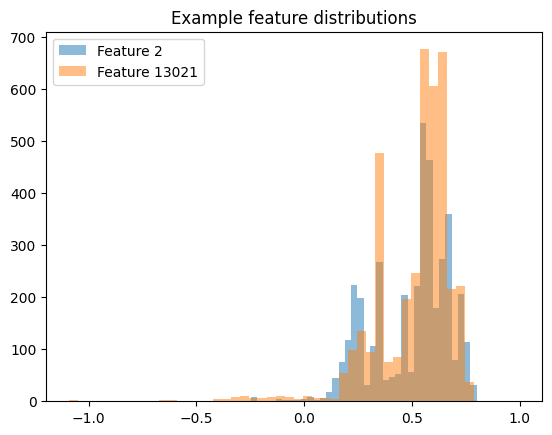

In [20]:
features = data.drop(columns="ID")
plt.hist(features.iloc[:, 2], bins=50, alpha=0.5, label="Feature 2")
plt.hist(features.iloc[:, 13021], bins=50, alpha=0.5, label="Feature 13021")
plt.legend()
plt.title("Example feature distributions")
plt.show()

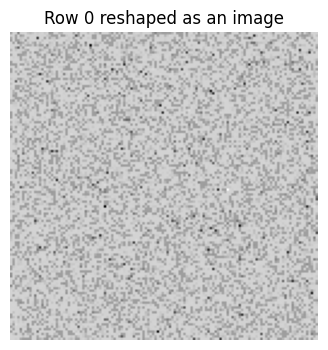

In [21]:
# 16384 = 128 × 128. Coincidence? This may be a flattened grayscale image...
row = data.iloc[0, 1:].astype(float).to_numpy()
image = row.reshape(128, 128).T
image = (image - image.min()) / (image.max() - image.min() + 1e-8)

plt.figure(figsize=(4, 4))
plt.imshow(image, cmap="gray")
plt.title("Row 0 reshaped as an image")
plt.axis("off")
plt.show()

# If it really is an image, then pixels look scrambled.
# The true order may be encoded elsewhere. Maybe the dropped row contained important information?

In [22]:
# Kaggle submission format. The cluster ids here are just placeholders and do not hint at k.
sample_submission = pd.read_csv("sample_submission.csv")
sample_submission.head()

,ID,cluster
0,0,2
1,1,6
2,2,3
3,3,3
4,4,8


In [23]:
# ====================================
# YOUR CODE GOES HERE
# ====================================

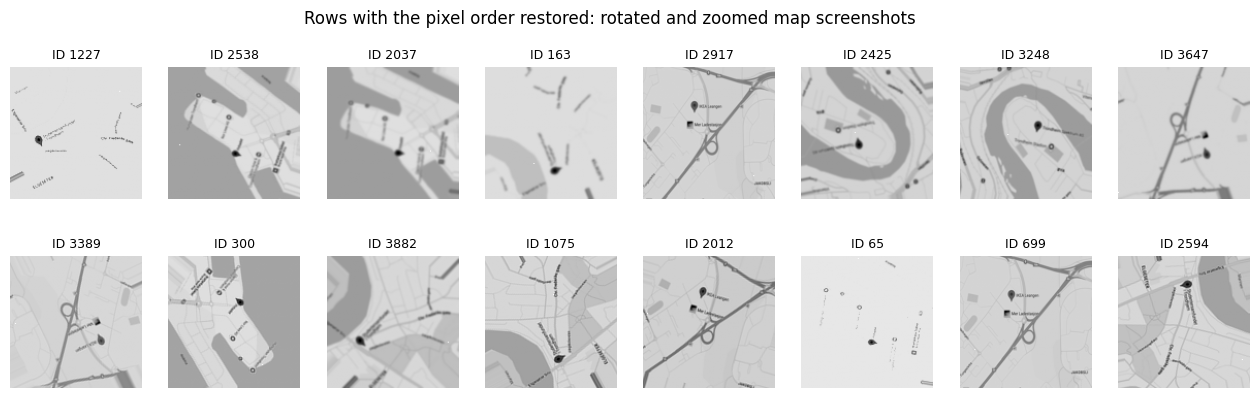

In [24]:
# The header row we skipped holds the original pixel index of each column. Undo the shuffle.
header = pd.read_csv("unsupervised_data.csv", nrows=0).columns
order = np.argsort([int(c.split("_")[1]) for c in header])
pixels = features.to_numpy(dtype=np.float32)[:, order]
images = pixels.reshape(-1, 128, 128)

fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, i in zip(axes.flat, np.random.default_rng(SEED).choice(len(images), 16, replace=False)):
    ax.imshow(images[i], cmap="gray")
    ax.set_title(f"ID {i}", fontsize=9)
    ax.axis("off")
plt.suptitle("Rows with the pixel order restored: rotated and zoomed map screenshots")
plt.show()

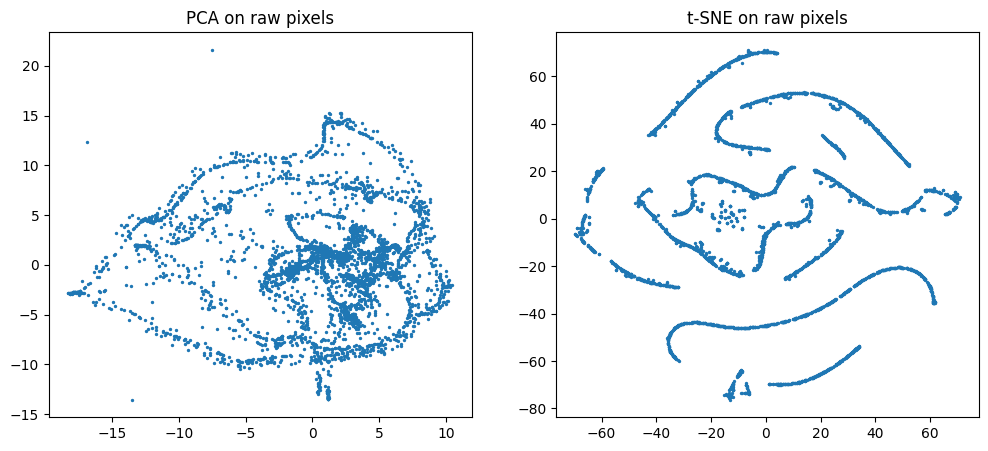

In [25]:
# Baseline: PCA and t-SNE on raw pixels
pca_raw = PCA(50, random_state=SEED).fit(pixels)
Z_raw = pca_raw.transform(pixels)
T_raw = TSNE(2, random_state=SEED, init="pca").fit_transform(Z_raw)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(Z_raw[:, 0], Z_raw[:, 1], s=2)
ax[0].set_title("PCA on raw pixels")
ax[1].scatter(T_raw[:, 0], T_raw[:, 1], s=2)
ax[1].set_title("t-SNE on raw pixels")
plt.show()

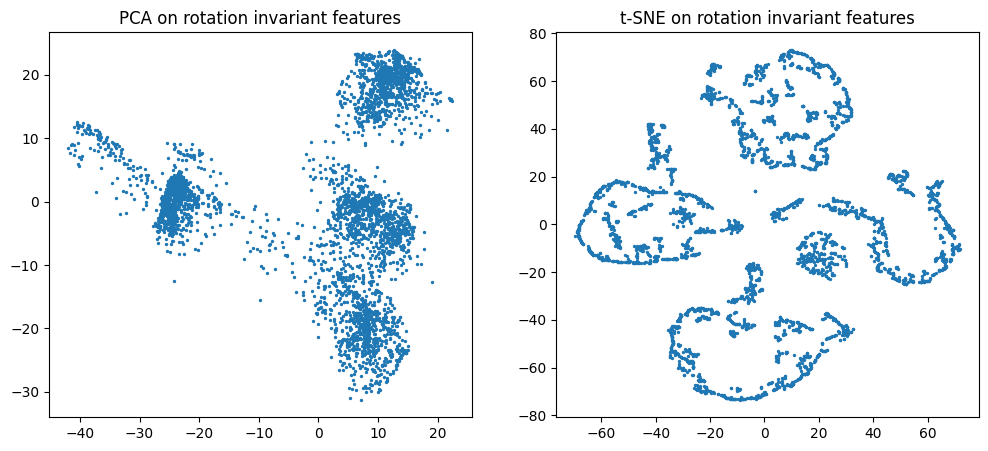

In [26]:
def fourier_mellin(imgs, n_r=48, n_t=64):
    """Translation and rotation invariant descriptor.

    |FFT| removes translation. Sampling it on a log-polar grid turns rotation into a cyclic
    shift along the angle axis (and zoom into a shift along log-radius). Taking |FFT| along
    the angle axis then removes rotation.
    """
    imgs = imgs - imgs.mean(axis=(1, 2), keepdims=True)
    window = np.outer(np.hanning(128), np.hanning(128))
    spec = np.log1p(np.abs(np.fft.fftshift(np.fft.fft2(imgs * window), axes=(1, 2))))
    r = np.exp(np.linspace(np.log(2), np.log(63), n_r))
    t = np.linspace(0, np.pi, n_t, endpoint=False)  # |FFT| is point symmetric
    R, Th = np.meshgrid(r, t, indexing="ij")
    coords = [64 + R * np.sin(Th), 64 + R * np.cos(Th)]
    polar = np.stack([map_coordinates(s, coords, order=1) for s in spec])
    return np.abs(np.fft.rfft(polar, axis=2)).reshape(len(imgs), -1)


fm = fourier_mellin(images)
Z = PCA(50, random_state=SEED).fit_transform(StandardScaler().fit_transform(np.log1p(fm)))
T = TSNE(2, random_state=SEED, init="pca").fit_transform(Z)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(Z[:, 0], Z[:, 1], s=2)
ax[0].set_title("PCA on rotation invariant features")
ax[1].scatter(T[:, 0], T[:, 1], s=2)
ax[1].set_title("t-SNE on rotation invariant features")
plt.show()

In [27]:
# Choosing k: silhouette score and cluster sizes for KMeans on the first 20 components
rows = []
for k in range(2, 11):
    lab = KMeans(k, n_init=10, random_state=SEED).fit_predict(Z[:, :20])
    rows.append({"k": k, "silhouette": silhouette_score(Z[:, :20], lab), "sizes": sorted(np.bincount(lab), reverse=True)})
pd.DataFrame(rows)

,k,silhouette,sizes
0,2,0.239388,"[2909, 1091]"
1,3,0.303082,"[1918, 1082, 1000]"
2,4,0.375161,"[1086, 1001, 1000, 913]"
3,5,0.378851,"[1001, 1000, 907, 869, 223]"
4,6,0.354042,"[1001, 1000, 869, 698, 224, 208]"
5,7,0.331588,"[1001, 869, 774, 698, 226, 224, 208]"
6,8,0.334316,"[1001, 869, 698, 554, 224, 224, 222, 208]"
7,9,0.245316,"[774, 698, 605, 530, 395, 340, 227, 223, 208]"
8,10,0.252517,"[697, 626, 540, 461, 448, 331, 249, 221, 219, ..."


KMeans sizes:   [1086 1001 1000  913]
DBSCAN sizes:   [ 999  999 1002 1000]  noise points: 0
Spectral sizes: [1001 1000  999 1000]
Agreement KMeans vs spectral: 0.978
Agreement DBSCAN vs spectral: 0.9995


,dims,eps,clusters,noise,agreement with spectral
0,5,4,8,191,0.93400
1,5,6,6,26,0.99025
2,5,8,4,3,0.99925
3,5,10,4,0,0.99950
4,20,4,97,1861,0.30200
5,20,6,54,1150,0.45075
6,20,8,36,583,0.71600
7,20,10,15,205,0.91150


spectral n_neighbors=10, dims=10: agreement with final = 0.9998
spectral n_neighbors=15, dims=20: agreement with final = 1.0000


spectral n_neighbors=30, dims=30: agreement with final = 0.9998


spectral n_neighbors=50, dims=50: agreement with final = 0.9998


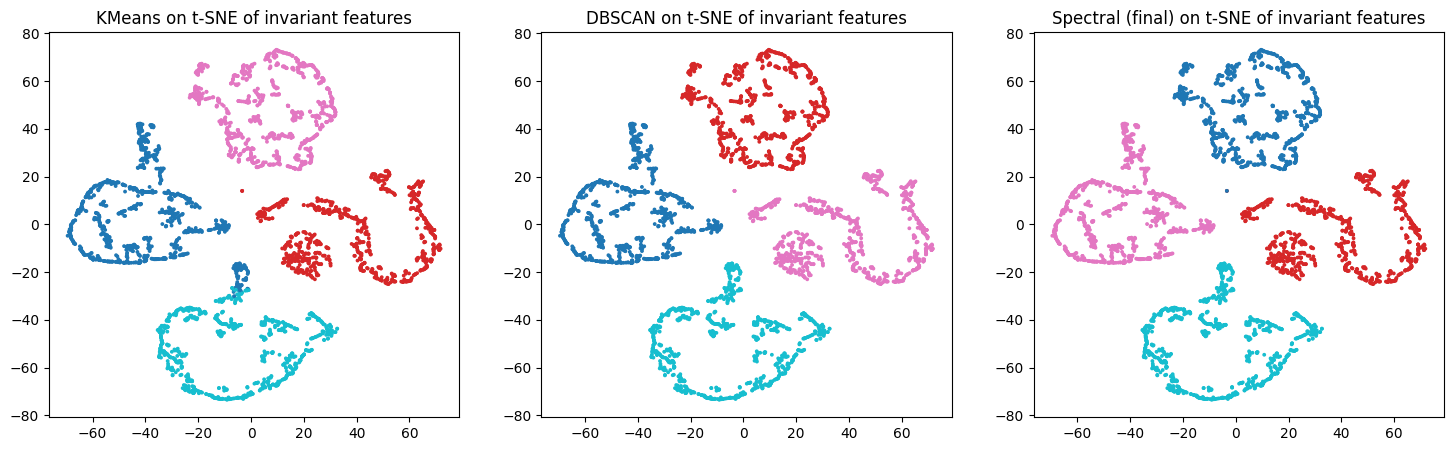

In [28]:
# KMeans vs DBSCAN vs spectral clustering (kNN graph) with k = 4
from scipy.optimize import linear_sum_assignment
from sklearn.metrics.cluster import contingency_matrix


def agreement(a, b):
    """Label invariant agreement between two clusterings (same metric as Kaggle)."""
    c = contingency_matrix(a, b)
    r, k = linear_sum_assignment(-c)
    return c[r, k].sum() / len(a)


km = KMeans(4, n_init=10, random_state=SEED).fit_predict(Z[:, :20])
db = DBSCAN(eps=10, min_samples=5).fit_predict(Z[:, :5])  # density based, needs fewer dims (see sweep below)
sc = SpectralClustering(4, affinity="nearest_neighbors", n_neighbors=20, random_state=SEED).fit_predict(Z[:, :20])

print("KMeans sizes:  ", np.bincount(km))
print("DBSCAN sizes:  ", np.bincount(db[db >= 0]), " noise points:", (db < 0).sum())
print("Spectral sizes:", np.bincount(sc))
print("Agreement KMeans vs spectral:", agreement(sc, km))
print("Agreement DBSCAN vs spectral:", agreement(sc, db))

rows = []
for dims in [5, 20]:
    for eps in [4, 6, 8, 10]:
        lab = DBSCAN(eps=eps, min_samples=5).fit_predict(Z[:, :dims])
        rows.append({"dims": dims, "eps": eps, "clusters": len(set(lab) - {-1}), "noise": int((lab < 0).sum()),
                     "agreement with spectral": agreement(sc, lab)})
display(pd.DataFrame(rows))

# Robustness: spectral clustering is stable across hyperparameters
for nn_, d in [(10, 10), (15, 20), (30, 30), (50, 50)]:
    alt = SpectralClustering(4, affinity="nearest_neighbors", n_neighbors=nn_, random_state=SEED).fit_predict(Z[:, :d])
    print(f"spectral n_neighbors={nn_}, dims={d}: agreement with final = {agreement(sc, alt):.4f}")

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, lab, name in zip(ax, [km, db, sc], ["KMeans", "DBSCAN", "Spectral (final)"]):
    a.scatter(T[:, 0], T[:, 1], c=lab, s=3, cmap="tab10")
    a.set_title(f"{name} on t-SNE of invariant features")
plt.show()

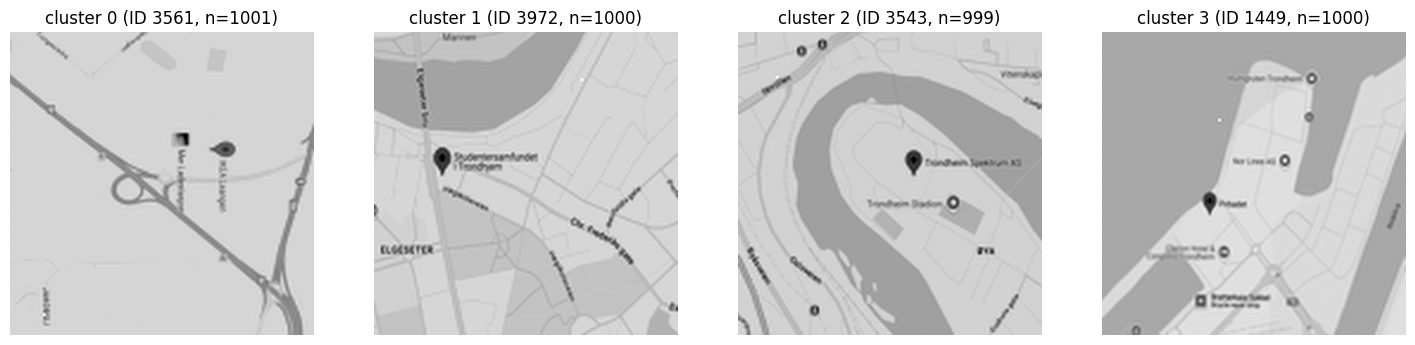

In [29]:
# Name the clusters. The view that differs most from its neighbours (lowest LOF) is usually an
# unrotated, unzoomed screenshot where the pin label can be read. One per cluster:
from sklearn.neighbors import LocalOutlierFactor

lof = LocalOutlierFactor(20).fit(Z[:, :20]).negative_outlier_factor_
canonical = {c: min(np.where(sc == c)[0], key=lambda i: lof[i]) for c in range(4)}
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, (c, i) in zip(axes, canonical.items()):
    ax.imshow(images[i], cmap="gray", interpolation="lanczos")
    ax.set_title(f"cluster {c} (ID {i}, n={np.sum(sc == c)})")
    ax.axis("off")
plt.show()

In [30]:
# Labels read from the pins above. One reference ID per facility:
references = {3268: "IKEA Leangen", 3972: "Studentersamfundet i Trondheim", 3543: "Trondheim Spektrum", 1449: "Pirbadet"}
names = {sc[i]: name for i, name in references.items()}
names

{np.int32(0): 'IKEA Leangen',
 np.int32(1): 'Studentersamfundet i Trondheim',
 np.int32(2): 'Trondheim Spektrum',
 np.int32(3): 'Pirbadet'}

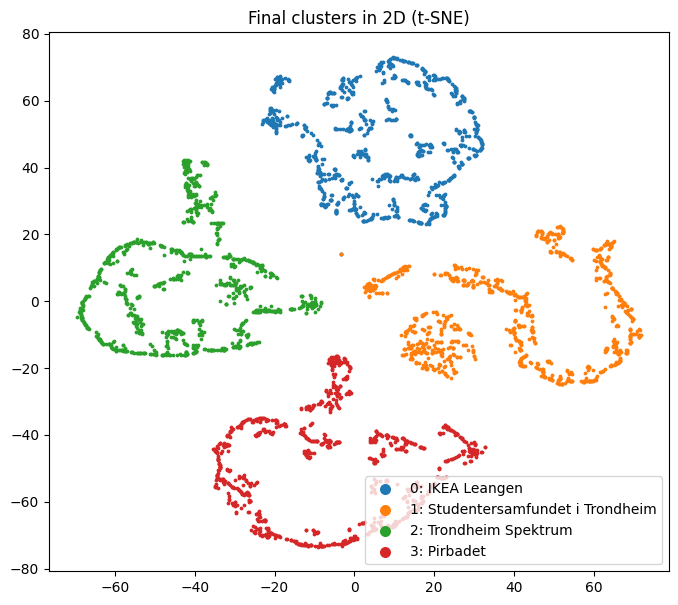

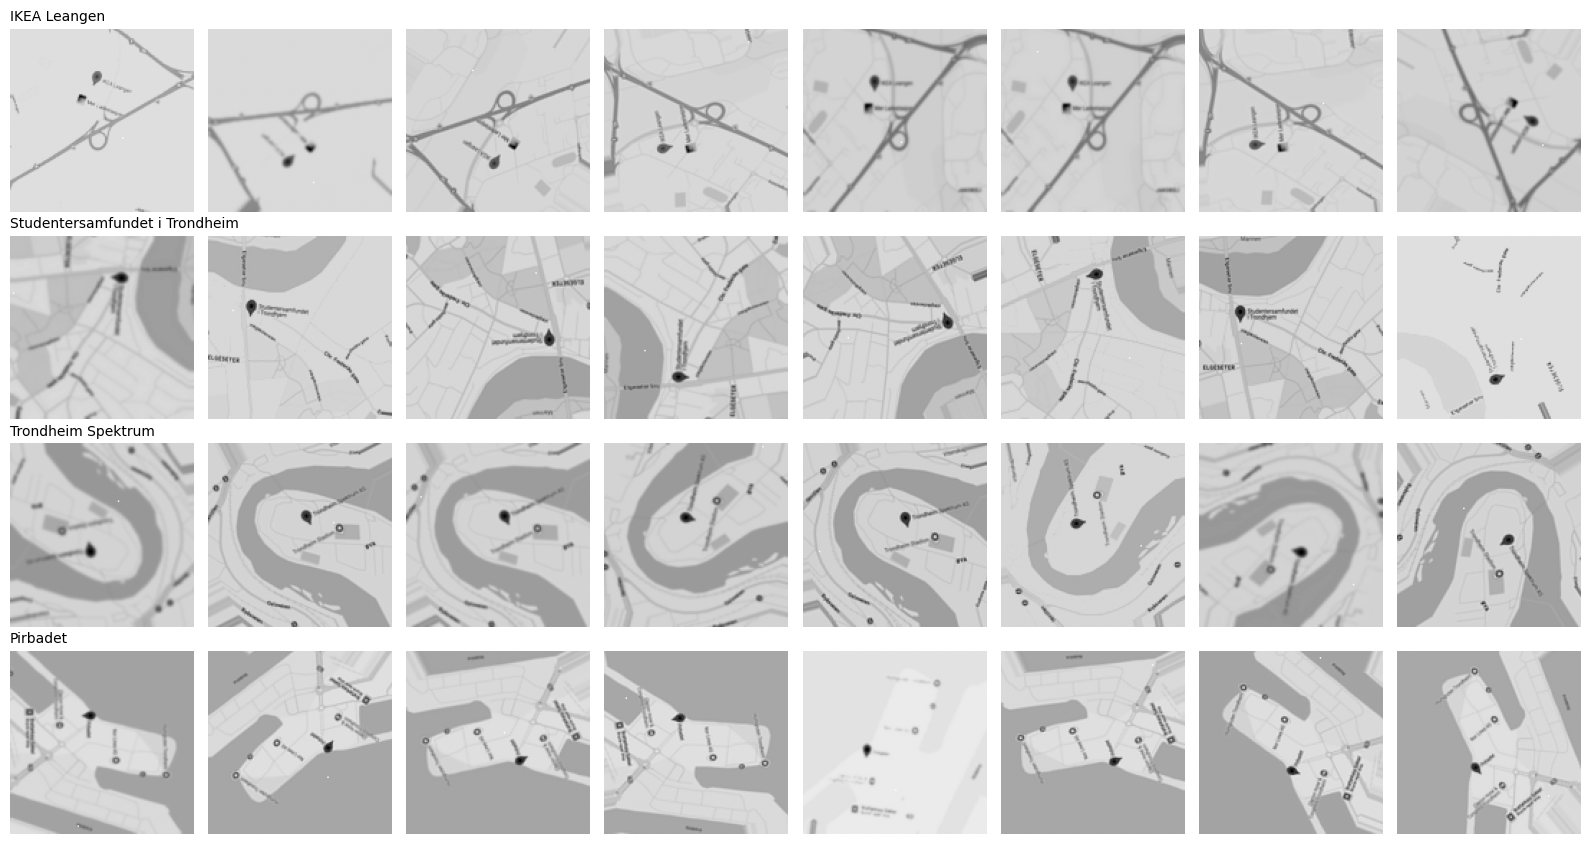

In [31]:
fig, ax = plt.subplots(figsize=(8, 7))
for c in range(4):
    m = sc == c
    ax.scatter(T[m, 0], T[m, 1], s=3, label=f"{c}: {names[c]}")
ax.legend(markerscale=4)
ax.set_title("Final clusters in 2D (t-SNE)")
plt.show()

fig, axes = plt.subplots(4, 8, figsize=(16, 8.5))
rng = np.random.default_rng(SEED)
for c in range(4):
    for ax, i in zip(axes[c], rng.choice(np.where(sc == c)[0], 8, replace=False)):
        ax.imshow(images[i], cmap="gray")
        ax.axis("off")
    axes[c, 0].set_title(names[c], loc="left", fontsize=10)
plt.tight_layout()
plt.show()

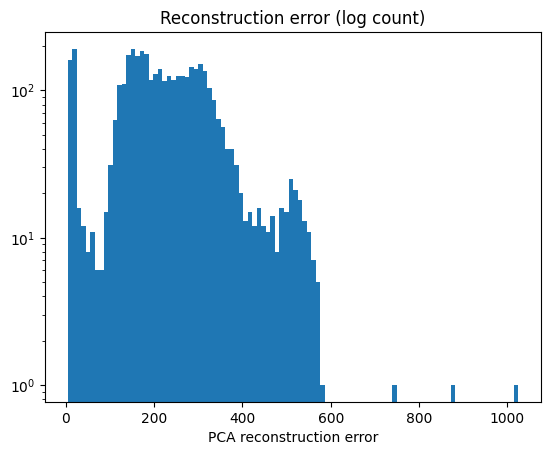

Largest errors: [1025.  876.  746.  578.  574.  572.]
Anomalous IDs: [ 968 2117 2251] errors: [ 746. 1025.  876.] median: 217.0


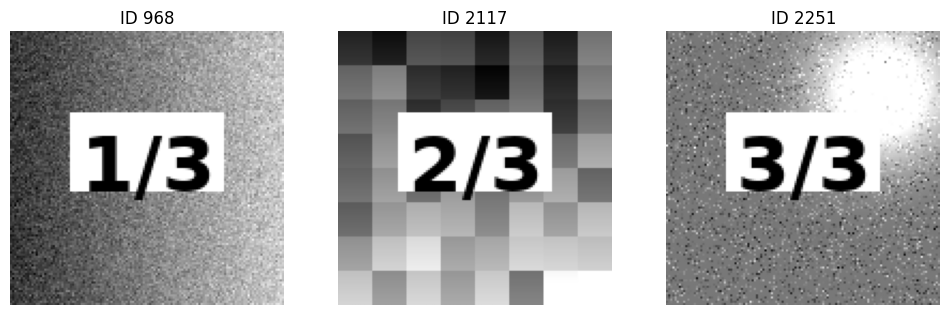

In [32]:
# Anomaly detection: rows that the 50 component PCA of the map images cannot reconstruct
recon_error = ((pixels - pca_raw.inverse_transform(Z_raw)) ** 2).sum(axis=1)
plt.hist(recon_error, bins=100, log=True)
plt.xlabel("PCA reconstruction error")
plt.title("Reconstruction error (log count)")
plt.show()

print("Largest errors:", np.sort(recon_error)[::-1][:6].round(0))
threshold = 650  # clear gap between the three largest errors and the rest
anomalies = np.where(recon_error > threshold)[0]
print("Anomalous IDs:", anomalies, "errors:", recon_error[anomalies].round(0), "median:", np.median(recon_error).round(0))

fig, axes = plt.subplots(1, len(anomalies), figsize=(4 * len(anomalies), 4))
for ax, i in zip(np.atleast_1d(axes), anomalies):
    ax.imshow(images[i], cmap="gray")
    ax.set_title(f"ID {i}")
    ax.axis("off")
plt.show()

In [33]:
final_labels = sc.copy()
final_labels[anomalies] = 4  # the non-map rows form their own group
submission = pd.DataFrame({"ID": data["ID"], "cluster": final_labels})
submission.to_csv("submission.csv", index=False)
print(submission["cluster"].value_counts().sort_index())
submission.head()

cluster
0     999
1     999
2     999
3    1000
4       3
Name: count, dtype: int64


,ID,cluster
0,0,2
1,1,0
2,2,2
3,3,0
4,4,1


### ❓ Which dimensionality reduction methods helped you choose *k*? Compare PCA and t-SNE in 2D.

**On raw pixels**, PCA gives one shapeless cloud and t-SNE gives many thin curved strands. Each strand is one place seen under continuously changing rotation/zoom, so raw pixels group images by orientation rather than by location, and counting strands would overestimate k.

**On the rotation invariant Fourier-Mellin features** (|FFT| → log-polar resampling → |FFT| over angle), both methods show the structure. PCA shows a few overlapping groups, and t-SNE shows **4** well separated groups. KMeans silhouette scores are highest for k = 4 and 5 (0.375 and 0.379), but k = 5 only splits off a group of 223 points from one of the clusters. With k = 4 all clusters have about 1000 rows (1001/1000/999/1000 with spectral clustering), and this is consistent across methods. **k = 4.**

**PCA vs t-SNE in 2D:** PCA is linear and keeps global variance. It is fast, deterministic and can transform new data, but in 2D the curved clusters overlap. t-SNE is non linear and keeps local neighbourhoods, so it separates the clusters clearly, but distances between clusters and cluster sizes in the plot are not meaningful, the result depends on perplexity and seed, and it cannot map new points. We used PCA (50 components) as preprocessing and t-SNE for visualization.


### ❓ Which clustering algorithm and hyperparameters did you use? Compare KMeans and DBSCAN.

**Final:** spectral clustering with k = 4, `affinity="nearest_neighbors"`, `n_neighbors=20`, on the first 20 PCA components of the standardized, log transformed Fourier-Mellin features. It builds a kNN graph and clusters connected manifolds, which fits the data: each place forms a curved, elongated manifold (rotation/zoom), not a round blob. It is stable, with ≥ 99.98% agreement across n_neighbors 10 to 50 and 10 to 50 dimensions.

**KMeans** (k = 4) assumes convex, similarly sized spherical clusters. It cuts across the elongated manifolds, giving sizes 1086/1001/1000/913 and only 97.8% agreement with spectral, which is below the 99% target.

**DBSCAN** does not need k and marks noise, but it is very sensitive to `eps` and dimensionality. On 20 dimensions it breaks the data into 15 to 97 clusters with hundreds of noise points (distances concentrate in high dimensions and densities vary). On 5 dimensions with `eps=10, min_samples=5` it finds exactly 4 clusters, no noise, and 99.95% agreement with spectral clustering. This is an independent confirmation of the result, but finding those hyperparameters required a sweep.


### ❓ What is the hidden modality? How does this impact dimensionality reduction and clustering?

Each row is a **128×128 grayscale image** (16 384 = 128²) whose pixels have been shuffled. The skipped header row holds the original pixel index (`col_<index>`), and sorting the columns by it restores the images. They are **map screenshots of four places in Trondheim**, each with a pin, under random rotation, zoom, shift, blur and contrast.

**Impact:**
- Euclidean distance between images is dominated by rotation and zoom, not by which place is shown. Two rotations of the same map are further apart than two different maps at the same angle. PCA/t-SNE on raw pixels therefore produce orientation strands, and KMeans on pixels fails.
- Shuffling the pixels does not change Euclidean distances or PCA (it is only a permutation of features). However, it destroys the spatial structure needed for image specific features and for looking at the data.
- Knowing it is an image lets us build features that are invariant to the nuisance transforms (Fourier-Mellin: translation and rotation invariance). After that the four places separate and simple clustering works.


### ❓ List the facilities in Trondheim and how you identified them.

| Cluster | Facility | Landmarks in the map |
|---|---|---|
| 0 | **IKEA Leangen** | E6 motorway with a loop interchange, "Mer Ladestasjon" next to the pin |
| 1 | **Studentersamfundet i Trondheim** | Elgeseter, Elgeseter gate, Nidelva at the top, Chr. Frederiks gate |
| 2 | **Trondheim Spektrum** | On Øya inside the bend of Nidelva, next to Trondheim Stadion |
| 3 | **Pirbadet** | Brattøra harbour, Hurtigruten terminal, Clarion Hotel & Congress |

**How:** after clustering, for each cluster we picked the view that differs most from its neighbours (lowest LOF score). These are typically the unrotated, unzoomed screenshots, where the pin label can be read. We read the labels and checked them against landmarks (river shapes, motorway, harbour). Sample images from each cluster confirm that every cluster shows the same place.


### ❓ How did you detect the rows that do not belong, and what were they?

**Method:** PCA with 50 components fitted on the raw pixels, followed by the reconstruction error of each row. The 50 components capture the structure that map images share, so a row that is not a map cannot be reconstructed well. The histogram shows a clear gap: three rows have errors 746 to 1025, the median is 217 and the next largest is 578. A threshold of 650 separates them.

**What they are:** IDs **968, 2117 and 2251**. These are synthetic images with the text **"1/3"**, **"2/3"** and **"3/3"** on top of a noisy gradient, 8×8 pixelated blocks, and salt and pepper noise with a bright spot. They are not maps. In the submission they get their own cluster id (4). The Kaggle score was 0.99925 both with and without this separate cluster, so these rows do not seem to affect the score.


---

## Note: Clustering accuracy metric

Kaggle scores clustering with **label-invariant** accuracy: only the grouping matters, not the numeric ids.

If true labels are `[0, 0, 0, 1, 1, 1]` and you predict `[1, 1, 1, 0, 0, 0]`, accuracy is **1.0** because clusters match after renaming.

### How it is computed

1. Build a contingency matrix between true and predicted labels.
2. Find the best label matching (Hungarian algorithm / `linear_sum_assignment`).
3. Accuracy = matched points / total points.

---

In [34]:
import scipy.optimize
import sklearn.metrics


def calculate_clustering_accuracy(true_labels: np.ndarray, cluster_labels: np.ndarray) -> float:
    """Clustering accuracy with optimal permutation of cluster ids."""
    if true_labels.size != cluster_labels.size:
        raise ValueError("true_labels and cluster_labels must have the same length.")

    contingency = sklearn.metrics.cluster.contingency_matrix(true_labels, cluster_labels)
    row_ind, col_ind = scipy.optimize.linear_sum_assignment(-contingency)
    correct = contingency[row_ind, col_ind].sum()
    return correct / true_labels.size

In [35]:
true_labels = np.array([0, 1, 2, 0, 1, 2])
cluster_labels = np.array([1, 2, 0, 1, 2, 0])
calculate_clustering_accuracy(true_labels, cluster_labels)

np.float64(1.0)

In [36]:
# Single cluster in ground truth: accuracy is share of majority predicted cluster
true_labels = np.array([0, 0, 0, 0, 0, 0])
cluster_labels = np.array([1, 2, 0, 1, 2, 0])
calculate_clustering_accuracy(true_labels, cluster_labels)

np.float64(0.3333333333333333)

In [37]:
# Wrong number of groups: low accuracy
true_labels = np.array([1, 1, 1, 2, 2, 2])
cluster_labels = np.array([0, 0, 0, 0, 0, 0])
calculate_clustering_accuracy(true_labels, cluster_labels)

np.float64(0.5)